# Phase 4 – Court Judgment Prediction (CJPE) with the Phase-1 legal LM
Binary classification of long Indian court judgments (0/1). Train on `train.json`, select on `dev.json`, report on `test.json`.

**Pipeline:** tail-anchored chunks → frozen bottom 50% (BOT50) → attention pooling → classifier. 

# Citations
1) LoRMA: Low-Rank Multiplicative Adaptation for LLMs, Bihany et. al.
2) LoRA: Low-Rank Adaptation of Large Language Models, Hu et. al.
3) AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning, Zhang et. al.
4) Layer freezing / unfreezing strategies (INT, BOT, TOP, ADT-L, ADT-H)
5) Distilling the Knowledge in a Neural Network, Hinton et. al.
6) A Systematic Investigation of Document Chunking
Strategies and Embedding Sensitivity, Shaukat et. al.
7) EXPLORING SELECTIVE LAYER FREEZING STRATEGIES IN TRANSFORMER FINE-TUNING: NLI CLASSIFIERS WITH SUB-3B PARAMETER MODELS
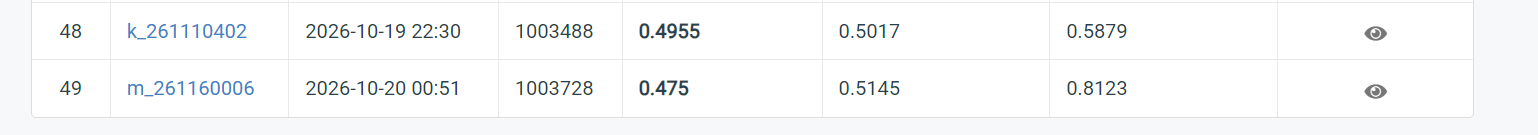

In [ ]:
!find /kaggle/input -name model.pt

In [ ]:
!pip install ijson
import os
import sys
import json
import math
import time
import random
import zipfile
from typing import List, Tuple, Dict, Any, Generator
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from tqdm.auto import tqdm
import numpy as np, ijson
from multiprocessing import Pool
import regex
!pip install -q scikit-learn pandas
!pip uninstall -y torchao

In [ ]:
HF_TOKEN = None
if "HF_TOKEN" in os.environ:
    HF_TOKEN = os.environ["HF_TOKEN"]
else:
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        HF_TOKEN = user_secrets.get_secret("HF")
        os.environ["HF_TOKEN"] = HF_TOKEN
        print("Successfully loaded HF_TOKEN from Kaggle Secrets.")
    except Exception as e:
        print(f"Note: Kaggle secrets not detected or HF key missing ({e}). Will attempt public access.")

if HF_TOKEN:
    try:
        from huggingface_hub import login
        login(token=HF_TOKEN)
        print("Huggingface hub authentication successful.")
    except Exception as err:
        print(f"HF Login warning: {err}")


print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device Count: {torch.cuda.device_count()}")
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
        
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

In [ ]:
# Config and paths
from huggingface_hub import HfApi

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = ["Phase_4_CJPE/Train/train.json", "Phase_4_CJPE/Train/dev.json"]
TEST_FILES  = ["Phase_4_CJPE/Test/test.json"]

VOCAB_SIZE = 33000
SEED = 67
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

SMOKE = False            # True = tiny end-to-end dry run (a few minutes) writing *_smoke outputs
SMOKE_STEPS = 6

# ---- paths
OUTPUT_DIR = "/kaggle/working/cs781_phase4" if os.path.exists("/kaggle") else "./outputs"
MODEL_PT   = "/kaggle/input/datasets/koooshiieee/phase2v2/model.pt"
TOK_DIR    = "/kaggle/working/tok_phase1"
TOK_REPO   = "DumbLad/legal-bpe-tokenizer-phase1-v2"
_sfx = "_smoke" if SMOKE else ""
CHECKPOINT_DIR  = os.path.join(OUTPUT_DIR, "model_checkpoint" + _sfx)
PREDICTION_PATH = os.path.join(OUTPUT_DIR, f"prediction{_sfx}.json")
SUBMISSION_ZIP  = os.path.join(OUTPUT_DIR, f"submission{_sfx}.zip")
LOSS_PLOT_PATH  = os.path.join(OUTPUT_DIR, f"training_curves{_sfx}.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ---- data / chunking
LOWERCASE = True                       # dev/test are lower-cased; train has mixed case -> match them
CHUNK_LEN, OVERLAP, N_CHUNKS = 1024, 100, 4   # 3 chunks from the end + 1 head chunk
HEAD_CH, TAIL_CH = 6000, 20000         # chars kept from the head/tail of very long docs before tokenising
HOLDOUT_DEV_FRAC = 0.5                 # share of dev (grouped by id) held out for threshold + checkpoint choice
DEV_REPEAT = 1                         # >1 upweights the remaining dev docs (closest in style to test)

# ---- model / optimisation (BOT50: bottom 50% of layers frozen, top 50% fully fine-tuned)
BOT_PCT = 50
LR_BB, LR_HEAD, WD, WARMUP, DROPOUT = 5e-5, 1e-3, 0.01, 0.06, 0.1
BS_MICRO, ACCUM, EVAL_BS = 8, 2, 16     # micro-batch (docs), accumulation steps -> 16 docs per update
MAX_EPOCHS, N_EVALS = 3, 4
TRAIN_BUDGET_SEC = 120 * 60

HF_OUT_REPO = "DumbLad/cs781-phase4-v2-cjpe"
if not SMOKE:
    HfApi(token=HF_TOKEN).create_repo(HF_OUT_REPO, repo_type="model", private=True, exist_ok=True)

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

def download_data():
    local_train_paths = []
    print("\nDownloading phase 4 training data.")
    for tf in TRAIN_FILES:
        try:
            p = hf_hub_download(repo_id = HF_DATASET_REPO, filename = tf, repo_type = "dataset", token = HF_TOKEN)
            local_train_paths.append(p)
            print(f"Downloaded: {tf}")
        except Exception as e:
            raise RuntimeError(f"Failed downloading training file {tf}: {e}") from e
            
    test_paths = []
    for tf in TEST_FILES:
        try:
            p = hf_hub_download(repo_id = HF_DATASET_REPO, filename = tf, repo_type = "dataset", token = HF_TOKEN)
            test_paths.append(p); print(f"Downloaded Test File: {tf}")
        except Exception as e:
            raise RuntimeError(f"Failed downloading test file {tf}: {e}") from e
    return local_train_paths, test_paths

In [ ]:
# List all files in the repository and filter for those containing "Phase_4"
all_files = HfApi(token=HF_TOKEN).list_repo_files(HF_DATASET_REPO, repo_type="dataset")
phase_4_files = [f for f in all_files if "Phase_4" in f]

print("Phase 4 files found:", phase_4_files)

# Then call your download function
train_paths, test_paths = download_data()
# inspect_json_files(train_paths, n=2)

In [ ]:
import os

# 1. Map filenames to their full local paths and set up test variables
P = {os.path.basename(p): p for p in train_paths}
TEST = test_paths

# 2. Assert that train.json and dev.json are present in train files, and exactly 1 test file exists
assert {"train.json", "dev.json"} <= set(P) and len(TEST) == 1, \
    f"Assertion failed! Found train files: {list(P.keys())}, Test files count: {len(TEST)}"

print(P.keys(), TEST)

In [ ]:
%%writefile bpe_tokenizer.py
#!/usr/bin/env python3
import os, json, regex
from typing import Dict, List, Tuple
from collections import Counter, defaultdict
from tqdm.auto import tqdm

import regex


_PAT = regex.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")


class PureByteLevelBPETokenizer:
    def __init__(self, vocab_size: int = 33000):
        self.vocab_size = vocab_size
        self.special_tokens = ["<pad>", "<unk>", "<s>", "</s>", "<mask>"]

        self.encoder: Dict[bytes, int] = {}
        self.decoder: Dict[int, bytes] = {}
        self.merges: Dict[Tuple[bytes, bytes], bytes] = {}       # pair -> merged token
        self.merge_ranks: Dict[Tuple[bytes, bytes], int] = {}    # pair -> order learned (lower = earlier)
        self._cache: Dict[str, List[int]] = {}

        self._init_base_vocab()

    def _init_base_vocab(self):
        for b in range(256):
            b_bytes = bytes([b])
            self.encoder[b_bytes] = b
            self.decoder[b] = b_bytes

        # special tokens
        for idx, token in enumerate(self.special_tokens, start=256):
            b_bytes = token.encode("utf-8")
            self.encoder[b_bytes] = idx
            self.decoder[idx] = b_bytes

    @property
    def pad_token_id(self) -> int:
        return self.encoder["<pad>".encode("utf-8")]

    @property
    def unk_token_id(self) -> int:
        return self.encoder["<unk>".encode("utf-8")]

    @property
    def bos_token_id(self) -> int:
        return self.encoder["<s>".encode("utf-8")]

    @property
    def eos_token_id(self) -> int:
        return self.encoder["</s>".encode("utf-8")]

    # ------------------------------------------------------------------ training
    @staticmethod
    def _merge_word(word, a, b, new):
        out, i, n = [], 0, len(word)
        while i < n:
            if i < n - 1 and word[i] == a and word[i + 1] == b:
                out.append(new)
                i += 2
            else:
                out.append(word[i])
                i += 1
        return out

    def train_from_texts(self, texts: List[str], target_vocab_size: int = None, min_word_freq: int = 2):
        if target_vocab_size is None:
            target_vocab_size = self.vocab_size
        num_merges = target_vocab_size - len(self.encoder)
        print(f"\nTraining byte level BPE from scratch. Target merges: {num_merges:,} | Base Vocab: {len(self.encoder)}")

        # 1) pre-tokenize + count unique words (the BPE then runs on this small table, not the raw text)
        word_counts = Counter()
        for text in tqdm(texts, desc="Counting pre-tokens"):
            if text and text.strip():
                word_counts.update(_PAT.findall(text))

        words, freqs = [], []
        for w, c in word_counts.items():
            if c >= min_word_freq:
                words.append([bytes([b]) for b in w.encode("utf-8", "replace")])
                freqs.append(c)
        del word_counts
        print(f"Unique words used for merge learning: {len(words):,}")

        # 2) initial pair statistics (updated incrementally afterwards)
        pair_counts = defaultdict(int)
        where = defaultdict(set)
        for i, w in enumerate(tqdm(words, desc="Initial pair counts")):
            for p in zip(w, w[1:]):
                pair_counts[p] += freqs[i]
                where[p].add(i)

        # 3) merge loop
        pbar = tqdm(total=num_merges, desc="Learning BPE Merges", dynamic_ncols=True)
        for _ in range(num_merges):
            if not pair_counts:
                print("No more candidate pairs found to merge.")
                break

            best_pair, freq = max(pair_counts.items(), key=lambda kv: kv[1])
            if freq < 2:
                print(f"Stopping early: Most frequent pair frequency is {freq}")
                break

            a, b = best_pair
            merged_token = a + b
            self.merges[best_pair] = merged_token
            self.merge_ranks[best_pair] = len(self.merge_ranks)
            if merged_token not in self.encoder:          # two merge paths can give the same bytes
                new_id = len(self.encoder)
                self.encoder[merged_token] = new_id
                self.decoder[new_id] = merged_token

            for i in list(where[best_pair]):
                w, f = words[i], freqs[i]
                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    if pair_counts[p] <= 0:
                        del pair_counts[p]
                w = self._merge_word(w, a, b, merged_token)
                words[i] = w
                for p in zip(w, w[1:]):
                    pair_counts[p] += f
                    where[p].add(i)
            del where[best_pair]
            pair_counts.pop(best_pair, None)

            pbar.update(1)
            pbar.set_postfix({"vocab_size": len(self.encoder), "top_pair_freq": freq})

        pbar.close()
        self._cache.clear()
        print(f"Training finished! Final Vocab Size: {len(self.encoder):,}")

    # ------------------------------------------------------------------ encode / decode
    def _encode_word(self, word: str) -> List[int]:
        cached = self._cache.get(word)
        if cached is not None:
            return cached
        tokens = [bytes([b]) for b in word.encode("utf-8", "replace")]
        while len(tokens) >= 2:
            best_pair, best_rank = None, None
            for p in zip(tokens, tokens[1:]):
                r = self.merge_ranks.get(p)
                if r is not None and (best_rank is None or r < best_rank):
                    best_pair, best_rank = p, r
            if best_pair is None:
                break
            tokens = self._merge_word(tokens, best_pair[0], best_pair[1], self.merges[best_pair])
        ids = [self.encoder.get(t, self.unk_token_id) for t in tokens]
        if len(self._cache) < 1_000_000:
            self._cache[word] = ids
        return ids

    def encode(self, text: str) -> List[int]:
        ids: List[int] = []
        for word in _PAT.findall(text):
            ids.extend(self._encode_word(word))
        return ids

    def decode(self, token_ids: List[int]) -> str:
        raw_bytes = b"".join(self.decoder.get(i, b"<unk>") for i in token_ids)
        return raw_bytes.decode("utf-8", errors="replace")

    # ------------------------------------------------------------------ save / load
    def save(self, save_dir: str):
        os.makedirs(save_dir, exist_ok=True)
        vocab_path = os.path.join(save_dir, "vocab.json")
        merges_path = os.path.join(save_dir, "merges.json")
        config_path = os.path.join(save_dir, "tokenizer_config.json")

        # latin1 maps bytes 1:1 onto code points, so any byte string survives JSON
        ser_vocab = {k.decode("latin1"): v for k, v in self.encoder.items()}
        with open(vocab_path, "w", encoding="utf-8") as f:
            json.dump(ser_vocab, f, ensure_ascii=False, indent=2)

        # JSON (not a space-separated text file): tokens can contain spaces, newlines, \r, \xa0 ...
        ser_merges = [[p1.decode("latin1"), p2.decode("latin1")] for (p1, p2) in self.merges]  # in learned order
        with open(merges_path, "w", encoding="utf-8") as f:
            json.dump(ser_merges, f, ensure_ascii=False)

        config = {
            "tokenizer_class": "PureByteLevelBPETokenizer",
            "vocab_size": len(self.encoder),
            "special_tokens": self.special_tokens,
            "pad_token_id": self.pad_token_id,
            "bos_token_id": self.bos_token_id,
            "eos_token_id": self.eos_token_id
        }
        with open(config_path, "w", encoding="utf-8") as f:
            json.dump(config, f, indent=2)

        print(f"Tokenizer saved successfully to {save_dir}")

    @classmethod
    def load(cls, save_dir: str) -> "PureByteLevelBPETokenizer":
        tok = cls()
        with open(os.path.join(save_dir, "vocab.json"), "r", encoding="utf-8") as f:
            ser_vocab = json.load(f)
        tok.encoder = {k.encode("latin1"): v for k, v in ser_vocab.items()}
        tok.decoder = {v: k.encode("latin1") for k, v in ser_vocab.items()}

        tok.merges, tok.merge_ranks = {}, {}
        with open(os.path.join(save_dir, "merges.json"), "r", encoding="utf-8") as f:
            for rank, (s1, s2) in enumerate(json.load(f)):
                p1, p2 = s1.encode("latin1"), s2.encode("latin1")
                tok.merges[(p1, p2)] = p1 + p2
                tok.merge_ranks[(p1, p2)] = rank
        return tok


In [ ]:
%%writefile llama_scratch.py
"""
Llama-style decoder-only LM, written from scratch (no HF / no llama library).

Pieces: RMSNorm, RoPE (or ALiBi), grouped-query attention (GQA; MQA = n_kv_heads 1,
MHA = n_kv_heads == n_heads), SwiGLU MLP, pre-norm residual blocks, tied embeddings,
KV-cache generation with left-padded batches.

Only torch tensors/autograd/nn.Linear/nn.Embedding are used as building blocks.
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


# ----------------------------------------------------------------------------- config
@dataclass
class Config:
    vocab_size: int = 33000
    d_model: int = 1024
    n_layers: int = 16
    n_heads: int = 16
    n_kv_heads: int = 4          # 16 query heads share 4 KV heads (4 queries per KV head)
    ffn_hidden: int = 2560
    max_seq_len: int = 1024      # training context
    rope_cache_len: int = 4096   # RoPE table length (>= prompt + generated tokens)
    rope_theta: float = 10000.0
    norm_eps: float = 1e-5
    tie_embeddings: bool = True
    pos_enc: str = "rope"        # "rope" | "alibi"
    attn_impl: str = "manual"    # "manual" (hand-written softmax(QK^T)V) | "sdpa" (torch fused kernel, same math)


PRESETS = {
    # exact totals with vocab 33000, tied embeddings
    "v2_100m": dict(d_model=768, n_layers=12, n_heads=12, n_kv_heads=4, ffn_hidden=2048), # ~100.86M
    "target_150m": dict(d_model=896, n_layers=14, n_heads=14, n_kv_heads=2, ffn_hidden=2304), # ~142M 
    "base":  dict(d_model=1024, n_layers=16, n_heads=16, n_kv_heads=4, ffn_hidden=2560),  # ~201.6M
    "small": dict(d_model=1024, n_layers=12, n_heads=16, n_kv_heads=4, ffn_hidden=2816),  # ~169.1M
    "tiny":  dict(d_model=64,   n_layers=2,  n_heads=4,  n_kv_heads=2, ffn_hidden=128),   # smoke tests
}


def analytic_param_count(c: Config) -> int:
    """Closed-form parameter count (use it to size a model before building it)."""
    hd = c.d_model // c.n_heads
    attn = 2 * c.d_model * c.n_heads * hd + 2 * c.d_model * c.n_kv_heads * hd   # Wq,Wo + Wk,Wv
    mlp = 3 * c.d_model * c.ffn_hidden                                           # gate, up, down
    per_layer = attn + mlp + 2 * c.d_model                                       # + 2 RMSNorm
    total = per_layer * c.n_layers + c.vocab_size * c.d_model + c.d_model        # + embedding + final norm
    if not c.tie_embeddings:
        total += c.vocab_size * c.d_model
    return total


def count_params(model, verbose=True) -> int:
    """model.parameters() yields a tied (shared) tensor only once, so tied weights are counted once."""
    total = sum(p.numel() for p in model.parameters())
    if verbose:
        emb = model.tok_emb.weight.numel()
        blocks = sum(p.numel() for p in model.layers.parameters())
        print(f"total {total/1e6:.1f}M | transformer blocks {blocks/1e6:.1f}M | embedding {emb/1e6:.1f}M "
              f"({'tied with output head' if model.cfg.tie_embeddings else 'output head separate'}) "
              f"| analytic {analytic_param_count(model.cfg)/1e6:.1f}M")
    return total


# ----------------------------------------------------------------------------- RMSNorm
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()                                   # always normalise in fp32
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)


# ----------------------------------------------------------------------------- RoPE
def build_rope_cache(head_dim, max_len, theta):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))   # (hd/2,)
    t = torch.arange(max_len).float()
    freqs = torch.outer(t, inv_freq)                                                # (max_len, hd/2)
    return freqs.cos(), freqs.sin()


def apply_rope(x, cos, sin):
    """x: (B, H, T, hd); cos/sin: (T, hd/2). Rotates the two halves of each head vector (Llama layout)."""
    half = x.shape[-1] // 2
    xf = x.float()
    x1, x2 = xf[..., :half], xf[..., half:]
    cos = cos[None, None]
    sin = sin[None, None]
    out = torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.type_as(x)


# ----------------------------------------------------------------------------- ALiBi
def get_alibi_slopes(n_heads):
    def pow2(n):
        start = 2 ** (-8.0 / n)
        return [start ** (i + 1) for i in range(n)]
    if math.log2(n_heads).is_integer():
        s = pow2(n_heads)
    else:
        c = 2 ** math.floor(math.log2(n_heads))
        s = pow2(c) + pow2(2 * c)[0::2][: n_heads - c]
    return torch.tensor(s, dtype=torch.float32)


# ----------------------------------------------------------------------------- GQA
def repeat_kv(x, n_rep):
    """(B, n_kv, S, hd) -> (B, n_kv*n_rep, S, hd); query head h uses kv head h // n_rep."""
    if n_rep == 1:
        return x
    B, n_kv, S, hd = x.shape
    return x[:, :, None].expand(B, n_kv, n_rep, S, hd).reshape(B, n_kv * n_rep, S, hd)


class GQAttention(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        assert cfg.d_model % cfg.n_heads == 0 and cfg.n_heads % cfg.n_kv_heads == 0
        self.nh, self.nkv = cfg.n_heads, cfg.n_kv_heads
        self.hd = cfg.d_model // cfg.n_heads
        self.n_rep = self.nh // self.nkv
        self.impl = cfg.attn_impl
        self.wq = nn.Linear(cfg.d_model, self.nh * self.hd, bias=False)
        self.wk = nn.Linear(cfg.d_model, self.nkv * self.hd, bias=False)
        self.wv = nn.Linear(cfg.d_model, self.nkv * self.hd, bias=False)
        self.wo = nn.Linear(self.nh * self.hd, cfg.d_model, bias=False)

    def forward(self, x, cos, sin, alibi_slopes, key_valid, past, use_cache):
        B, T, _ = x.shape
        q = self.wq(x).view(B, T, self.nh, self.hd).transpose(1, 2)    # (B, nh,  T, hd)
        k = self.wk(x).view(B, T, self.nkv, self.hd).transpose(1, 2)   # (B, nkv, T, hd)
        v = self.wv(x).view(B, T, self.nkv, self.hd).transpose(1, 2)

        if cos is not None:                                            # RoPE on q and k (not v)
            q = apply_rope(q, cos, sin)
            k = apply_rope(k, cos, sin)

        if past is not None:                                           # cache holds only nkv heads
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        new_cache = (k, v) if use_cache else None
        S = k.shape[2]

        k = repeat_kv(k, self.n_rep)
        v = repeat_kv(v, self.n_rep)

        # relative distance of every (query, key) pair; keys j <= query position are visible
        qpos = torch.arange(S - T, S, device=x.device)
        kpos = torch.arange(S, device=x.device)
        rel = qpos[:, None] - kpos[None, :]                            # (T, S)
        allowed = (rel >= 0)[None, None]                               # (1, 1, T, S)
        if key_valid is not None:                                      # hide left-padding keys
            allowed = allowed & key_valid[:, None, None, :]
        bias = None
        if alibi_slopes is not None:
            bias = -alibi_slopes.view(1, -1, 1, 1) * rel.clamp(min=0).float()[None, None]   # (1, nh, T, S)

        if self.impl == "sdpa" and key_valid is None and T == S:      # training fast path
            if bias is None:
                out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
            else:
                m = bias.masked_fill(~allowed, torch.finfo(q.dtype).min).to(q.dtype)
                out = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        else:                                                          # hand-written attention
            scores = ((q * (self.hd ** -0.5)) @ k.transpose(-2, -1)).float()   # (B, nh, T, S)
            if bias is not None:
                scores = scores + bias
            scores = scores.masked_fill(~allowed, -1e30)               # finite, so a fully-masked pad row can't give NaN
            probs = torch.softmax(scores, dim=-1).to(v.dtype)
            out = probs @ v                                            # (B, nh, T, hd)

        out = out.transpose(1, 2).reshape(B, T, self.nh * self.hd)
        return self.wo(out), new_cache


# ----------------------------------------------------------------------------- SwiGLU
class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden):
        super().__init__()
        self.w_gate = nn.Linear(d_model, hidden, bias=False)
        self.w_up = nn.Linear(d_model, hidden, bias=False)
        self.w_down = nn.Linear(hidden, d_model, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))


# ----------------------------------------------------------------------------- block + model
class Block(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.attn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.attn = GQAttention(cfg)
        self.mlp_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.mlp = SwiGLU(cfg.d_model, cfg.ffn_hidden)

    def forward(self, x, cos, sin, alibi_slopes, key_valid, past, use_cache):
        h, new_cache = self.attn(self.attn_norm(x), cos, sin, alibi_slopes, key_valid, past, use_cache)
        x = x + h
        x = x + self.mlp(self.mlp_norm(x))
        return x, new_cache


class LlamaLM(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        assert cfg.pos_enc in ("rope", "alibi") and cfg.attn_impl in ("manual", "sdpa")
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.layers = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        if cfg.pos_enc == "rope":
            cos, sin = build_rope_cache(cfg.d_model // cfg.n_heads, cfg.rope_cache_len, cfg.rope_theta)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)
            self.alibi_slopes = None
        else:
            self.rope_cos = self.rope_sin = None
            self.register_buffer("alibi_slopes", get_alibi_slopes(cfg.n_heads), persistent=False)

        self.apply(self._init_weights)
        for name, p in self.named_parameters():       # GPT-2 style: shrink the residual-branch output projections
            if name.endswith("wo.weight") or name.endswith("w_down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, use_cache=False, cache=None, start_pos=0,
                key_valid=None, all_logits=False):
        """
        training:  model(x, targets=y) -> scalar loss
        inference: model(idx, use_cache=True, cache=..., start_pos=..., key_valid=...) -> (logits, cache)
                   logits are for the last position only unless all_logits=True.
        """
        B, T = idx.shape
        x = self.tok_emb(idx)
        cos = sin = None
        if self.cfg.pos_enc == "rope":
            assert start_pos + T <= self.cfg.rope_cache_len, "sequence longer than the RoPE table"
            cos = self.rope_cos[start_pos:start_pos + T]
            sin = self.rope_sin[start_pos:start_pos + T]

        new_caches = []
        for i, layer in enumerate(self.layers):
            past = cache[i] if cache is not None else None
            x, c = layer(x, cos, sin, self.alibi_slopes, key_valid, past, use_cache)
            new_caches.append(c)
        x = self.norm(x)

        if targets is not None:
            logits = self.lm_head(x)
            return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        logits = self.lm_head(x if all_logits else x[:, -1:, :])
        return logits, (new_caches if use_cache else None)


# ----------------------------------------------------------------------------- generation
@torch.no_grad()
def generate(model, prompts, max_new_tokens, eos_id, pad_id, temperature=0.1, top_k=30,
             top_p=0.95, rep_penalty=1.2, ban_eos=True):
    """
    prompts: list of lists of token ids (any lengths). Left-pads them into one batch, runs one prefill,
    then decodes with a KV cache. Returns a list of lists of generated ids (EOS / padding removed).
    temperature <= 0 -> greedy.
    """
    model.eval()
    device = next(model.parameters()).device
    V = model.cfg.vocab_size
    B = len(prompts)
    L = max(len(p) for p in prompts)
    ids = torch.full((B, L), pad_id, dtype=torch.long, device=device)
    key_valid = torch.zeros(B, L, dtype=torch.bool, device=device)
    seen = torch.zeros(B, V, dtype=torch.bool, device=device)
    for b, p in enumerate(prompts):
        t = torch.tensor(p, dtype=torch.long, device=device)
        ids[b, L - len(p):] = t
        key_valid[b, L - len(p):] = True
        seen[b, t] = True

    out = [[] for _ in range(B)]
    finished = torch.zeros(B, dtype=torch.bool, device=device)
    amp = torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda"))
    with amp:
        logits, cache = model(ids, use_cache=True, key_valid=key_valid, start_pos=0)
        for step in range(max_new_tokens):
            lg = logits[:, -1, :].float()
            if ban_eos:
                lg[:, eos_id] = float("-inf")
            if rep_penalty != 1.0:                                     # CTRL-style repetition penalty
                pen = torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty)
                lg = torch.where(seen, pen, lg)
            if temperature <= 0:
                nxt = lg.argmax(-1)
            else:
                lg = lg / temperature
                if top_k and top_k > 0:
                    kth = torch.topk(lg, min(top_k, V)).values[:, -1:]
                    lg = lg.masked_fill(lg < kth, float("-inf"))
                if top_p < 1.0:
                    sl, si = torch.sort(lg, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    drop = (pr.cumsum(-1) - pr) > top_p                # keep the token that crosses top_p
                    sl = sl.masked_fill(drop, float("-inf"))
                    lg = torch.full_like(lg, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(lg, dim=-1), 1).squeeze(1)

            nxt = torch.where(finished, torch.full_like(nxt, pad_id), nxt)
            for b in range(B):
                if not finished[b] and nxt[b].item() != eos_id:
                    out[b].append(int(nxt[b].item()))
            finished = finished | (nxt == eos_id)
            seen.scatter_(1, nxt[:, None], True)
            if bool(finished.all()):
                break
            key_valid = torch.cat([key_valid, torch.ones(B, 1, dtype=torch.bool, device=device)], dim=1)
            logits, cache = model(nxt[:, None], use_cache=True, cache=cache,
                                  start_pos=L + step, key_valid=key_valid)
    return out

In [ ]:
from huggingface_hub import hf_hub_download
for f in ["vocab.json","merges.json","tokenizer_config.json"]:
    hf_hub_download("DumbLad/legal-bpe-tokenizer-phase1-v2", f, repo_type="model",
                    local_dir=TOK_DIR, token=HF_TOKEN)

In [ ]:
import os
import json
import ijson
import numpy as np
from collections import Counter

# Use the paths your previous notebook cells already downloaded.
TRAIN_PATH = P["train.json"]
DEV_PATH   = P["dev.json"]
TEST_PATH  = TEST[0]

def audit_json_array(path, name, show_samples=3):
    label_counts = Counter()
    lengths = []
    ids = set()
    duplicate_ids = 0
    missing_id = 0
    missing_text = 0
    missing_label = 0
    empty_text = 0
    samples = []

    print(f"\n{'='*65}\n{name}: {os.path.basename(path)}")
    print(f"File size: {os.path.getsize(path) / (1024**2):.2f} MiB")

    with open(path, "rb") as f:
        for record in ijson.items(f, "item"):
            record_id = record.get("id")
            text = record.get("text")
            label = record.get("label")

            if record_id is None:
                missing_id += 1
            elif record_id in ids:
                duplicate_ids += 1
            else:
                ids.add(record_id)

            if text is None:
                missing_text += 1
                text = ""
            text = str(text)
            lengths.append(len(text))

            if not text.strip():
                empty_text += 1

            if label is None:
                missing_label += 1
            else:
                # Keep the original label value for now; inspect unexpected values.
                label_counts[str(label)] += 1

            if len(samples) < show_samples:
                samples.append({
                    "id": record_id,
                    "label": label,
                    "text_preview": text[:250]
                })

    lengths = np.asarray(lengths, dtype=np.int64)
    print("Records:", len(lengths))
    print("Label counts:", dict(label_counts))
    if len(lengths):
        print("Label proportions:",
              {k: round(v / len(lengths), 4)
               for k, v in label_counts.items()})
        print("Text length in characters:")
        for q in [0, 25, 50, 75, 90, 95, 99, 100]:
            print(f"  P{q:02}: {np.percentile(lengths, q):,.0f}")
    print("Missing IDs:", missing_id)
    print("Duplicate IDs:", duplicate_ids)
    print("Missing text fields:", missing_text)
    print("Empty/whitespace-only texts:", empty_text)
    print("Missing labels:", missing_label)
    print("Sample records:")
    for s in samples:
        print(json.dumps(s, ensure_ascii=False, indent=2))

    return {
        "ids": ids,
        "labels": label_counts,
        "count": len(lengths),
        "lengths": lengths
    }

train_audit = audit_json_array(TRAIN_PATH, "TRAIN")
dev_audit   = audit_json_array(DEV_PATH, "DEV / VALIDATION")
test_audit  = audit_json_array(TEST_PATH, "TEST")
print("\nTrain/dev ID overlap:",
      len(train_audit["ids"] & dev_audit["ids"]))
print("Train/test ID overlap:",
      len(train_audit["ids"] & test_audit["ids"]))
print("Dev/test ID overlap:",
      len(dev_audit["ids"] & test_audit["ids"]))

In [ ]:
# Load train/dev/test (streaming), dedupe, build the dev holdout
import hashlib, re
from collections import defaultdict

def _trunc(text):
    if len(text) <= HEAD_CH + TAIL_CH + 2000:
        return text                                    # tokenised in full
    head, tail = text[:HEAD_CH], text[-TAIL_CH:]
    m = re.search(r"\s", tail[:300])                   # start the tail at a word boundary
    if m: tail = tail[m.end():]
    return (head, tail)

def load_split(path, with_label):
    recs = []
    with open(path, "rb") as f:
        for r in tqdm(ijson.items(f, "item"), desc=os.path.basename(path)):
            text = str(r.get("text") or "")
            recs.append(dict(
                id=r["id"],
                label=int(r["label"]) if with_label else None,   # test labels are never read
                md5=hashlib.md5(text.encode("utf-8", "ignore")).hexdigest(),
                n_chars=len(text),
                has_upper=any(c.isupper() for c in text[:3000]),
                text=_trunc(text)))
    return recs

def dedupe(recs, name):
    groups = defaultdict(list)
    for r in recs: groups[r["md5"]].append(r)
    keep, n_dup, n_conf = [], 0, 0
    for g in groups.values():
        n_dup += len(g) - 1
        if len({x["label"] for x in g}) > 1:           # same text, different labels -> ambiguous, drop
            n_conf += len(g); continue
        keep.append(g[0])
    print(f"{name}: {len(recs)} -> {len(keep)} | duplicate copies: {n_dup} | dropped (conflicting labels): {n_conf}")
    return keep

train = dedupe(load_split(P["train.json"], True), "train")
dev   = dedupe(load_split(P["dev.json"],   True), "dev")
test_recs = load_split(TEST[0], False)                 # keep EVERY test record, in file order
assert len({r["id"] for r in test_recs}) == len(test_recs), "duplicate ids in test.json"

# remove cross-split text overlap (never train on dev/test text)
test_md5 = {r["md5"] for r in test_recs}
n0 = len(dev);   dev = [r for r in dev if r["md5"] not in test_md5];   print("dev docs also in test removed:", n0 - len(dev))
dev_md5 = {r["md5"] for r in dev}
n0 = len(train); train = [r for r in train if r["md5"] not in test_md5 and r["md5"] not in dev_md5]
print("train docs also in dev/test removed:", n0 - len(train))

# holdout = share of dev, grouped by id (dev is closest in style to test, and balanced)
ids = sorted({r["id"] for r in dev}); random.Random(SEED).shuffle(ids)
hold_ids  = set(ids[: int(len(ids) * HOLDOUT_DEV_FRAC)])
hold      = [r for r in dev if r["id"] in hold_ids]
dev_train = [r for r in dev if r["id"] not in hold_ids]

if SMOKE:
    train, dev_train, hold, test_recs = train[:300], dev_train[:40], hold[:60], test_recs[:16]

def _stats(name, recs):
    n = len(recs)
    pos = f"{np.mean([r['label'] for r in recs]):.3f}" if recs and recs[0]["label"] is not None else "n/a"
    print(f"{name:10s} n={n:6d} | pos rate {pos} | mixed-case share {np.mean([r['has_upper'] for r in recs]):.3f} "
          f"| median chars {np.median([r['n_chars'] for r in recs]):,.0f}")
for nm, rs in [("train", train), ("dev_train", dev_train), ("holdout", hold), ("test", test_recs)]: _stats(nm, rs)
c = Counter(r["id"] for r in train)
print("train ids shared by >1 distinct doc:", sum(v > 1 for v in c.values()))

In [ ]:
# Tokenise + chunk (anchored at the END of each judgment) with a process pool
import multiprocessing as mp
from bpe_tokenizer import PureByteLevelBPETokenizer

STRIDE = CHUNK_LEN - OVERLAP
_TOK = None
def _init_worker():
    global _TOK
    _TOK = PureByteLevelBPETokenizer.load(TOK_DIR)

def _enc(text):
    return _TOK.encode(text.lower() if LOWERCASE else text)

def _tail_windows(n, max_w):                           # windows counted backwards from the last token
    out, end = [], n
    while True:
        start = max(0, end - CHUNK_LEN)
        out.append((start, end))
        if start == 0 or len(out) >= max_w: break
        end -= STRIDE
    return out

def _chunk_job(text):
    if isinstance(text, tuple):                        # very long doc: (head slice, tail slice)
        head_ids = _enc(text[0])[:CHUNK_LEN]
        ids = _enc(text[1])
        wins = _tail_windows(len(ids), N_CHUNKS - 1)
        chunks = [ids[a:b] for a, b in wins]; pos = list(range(len(chunks)))
        chunks.append(head_ids); pos.append(N_CHUNKS - 1)
    else:
        ids = _enc(text)
        if not ids: ids = [_TOK.unk_token_id]
        wins = _tail_windows(len(ids), N_CHUNKS + 1)
        if len(wins) <= N_CHUNKS and wins[-1][0] == 0:     # whole doc fits in <= N_CHUNKS windows
            chunks = [ids[a:b] for a, b in wins]; pos = list(range(len(chunks)))
        else:                                              # last N-1 windows + head chunk
            chunks = [ids[a:b] for a, b in wins[:N_CHUNKS - 1]]; pos = list(range(len(chunks)))
            chunks.append(ids[:CHUNK_LEN]); pos.append(N_CHUNKS - 1)
    keep = [(c, p) for c, p in zip(chunks, pos) if len(c) > 0]
    if not keep: keep = [([_TOK.unk_token_id], 0)]
    return [np.asarray(c, dtype=np.uint16) for c, _ in keep], [p for _, p in keep]

def tokenize_docs(recs, desc):
    with mp.get_context("fork").Pool(min(4, os.cpu_count() or 1), initializer=_init_worker) as pool:
        out = list(tqdm(pool.imap(_chunk_job, [r["text"] for r in recs], chunksize=16), total=len(recs), desc=desc))
    return [dict(id=r["id"], label=r["label"], chunks=c, pos=p) for r, (c, p) in zip(recs, out)]

t0 = time.time()
train_docs     = tokenize_docs(train,     "train")
dev_train_docs = tokenize_docs(dev_train, "dev (train part)")
hold_docs      = tokenize_docs(hold,      "dev (holdout)")
test_docs      = tokenize_docs(test_recs, "test")
print(f"tokenised in {(time.time()-t0)/60:.1f} min")

for nm, ds in [("train", train_docs), ("holdout", hold_docs), ("test", test_docs)]:
    nt = [sum(len(c) for c in d["chunks"]) for d in ds]
    print(f"{nm:8s} docs={len(ds):6d} | mean tokens/doc {np.mean(nt):7.0f} | docs using all {N_CHUNKS} chunks: "
          f"{np.mean([len(d['chunks']) == N_CHUNKS for d in ds]):.2f}")
assert max(int(c.max()) for d in train_docs[:2000] for c in d["chunks"]) < VOCAB_SIZE

In [ ]:
# Load the Phase-2-v2 LM, sanity-check it, build the BOT50 classifier
sys.path.insert(0, os.getcwd())
from llama_scratch import Config, LlamaLM

tok = PureByteLevelBPETokenizer.load(TOK_DIR)
PAD = tok.pad_token_id
assert torch.cuda.is_available() or SMOKE, "GPU required"
ck = torch.load(MODEL_PT, map_location="cpu", weights_only=False)
cfg = Config(**ck["cfg"]); cfg.attn_impl = "sdpa"
print("ckpt step/val:", ck.get("step"), ck.get("val"), "| cfg:", ck["cfg"])
base = LlamaLM(cfg); base.load_state_dict(ck["model"]); del ck
base = base.to(device).eval()
print(f"layers={cfg.n_layers} d_model={cfg.d_model} pos_enc={cfg.pos_enc} max_seq_len={cfg.max_seq_len} "
      f"vocab(model)={cfg.vocab_size} vocab(tokenizer)={len(tok.encoder)}")
assert len(tok.encoder) <= cfg.vocab_size, "tokenizer vocab larger than model vocab"
if CHUNK_LEN > cfg.max_seq_len: print(f"WARNING: CHUNK_LEN {CHUNK_LEN} > trained context {cfg.max_seq_len}")

# --- sanity 1: tokenizer round trip on short raw docs
full = [r["text"] for r in train + hold if isinstance(r["text"], str) and len(r["text"]) < 20000][:20]
bad = sum(tok.decode(tok.encode(t)) != t for t in full)
print(f"tokenizer round-trip failures: {bad}/{len(full)}")

# --- sanity 2: LM next-token loss (Phase-1 val loss was ~2-2.5; > 5 means wrong tokenizer/checkpoint)
@torch.no_grad()
def lm_loss(ids):
    if len(ids) < 8: return float("nan")
    x = torch.tensor([ids[:-1]], device=device); y = torch.tensor([ids[1:]], device=device)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        return base(x, targets=y).item()
hold_l = [lm_loss(d["chunks"][0][:512].astype(np.int64).tolist()) for d in hold_docs[:8]]
print(f"LM loss on holdout chunks (dev style, {'lower-cased' if LOWERCASE else 'raw'}): {np.nanmean(hold_l):.3f}")
mixed = [r for r in train if r["has_upper"]][:8]
def _head(r): return (r["text"][0] if isinstance(r["text"], tuple) else r["text"])[:2000]
if mixed:
    raw = np.nanmean([lm_loss(tok.encode(_head(r))[:512]) for r in mixed])
    low = np.nanmean([lm_loss(tok.encode(_head(r).lower())[:512]) for r in mixed])
    print(f"LM loss on mixed-case train docs: raw {raw:.3f} vs lower-cased {low:.3f}")
assert np.nanmean(hold_l) < 5.0, "LM loss too high: wrong tokenizer or checkpoint"
for lst in (train, dev_train, hold, test_recs):        # free the raw text
    for r in lst: r["text"] = None

# --- BOT50 classifier
class CJPEModel(nn.Module):
    def __init__(self, base, n_frozen, n_pos, dropout=0.1):
        super().__init__()
        self.base, self.n_frozen = base, n_frozen
        d = base.cfg.d_model
        self.ln = nn.LayerNorm(2 * d)
        self.pos_emb = nn.Embedding(n_pos, 2 * d)
        self.att_w = nn.Linear(2 * d, d)
        self.att_v = nn.Linear(d, 1, bias=False)
        self.drop = nn.Dropout(dropout)
        self.cls = nn.Linear(2 * d, 1)
        nn.init.normal_(self.pos_emb.weight, std=0.02)

    def encode(self, idx):                             # (n, T) -> (n, T, d); frozen bottom half runs without grad
        b = self.base; T = idx.shape[1]
        x = b.tok_emb(idx)
        if b.cfg.pos_enc == "rope": cos, sin, slopes = b.rope_cos[:T], b.rope_sin[:T], None
        else: cos, sin, slopes = None, None, b.alibi_slopes
        for i, layer in enumerate(b.layers):
            if i < self.n_frozen:
                with torch.no_grad(): x, _ = layer(x, cos, sin, slopes, None, None, False)
            else:
                x, _ = layer(x, cos, sin, slopes, None, None, False)
        return b.norm(x)

    def forward(self, ids, lens, pos):                 # ids (B,K,L) long, lens (B,K), pos (B,K)
        B, K, _ = ids.shape
        valid = lens > 0
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=ids.is_cuda):   # autocast is thread-local -> inside forward (DataParallel)
            fl = lens[valid]
            h = self.encode(ids[valid][:, : int(fl.max())])
            m = torch.arange(h.shape[1], device=h.device)[None] < fl[:, None]
            last = h[torch.arange(h.shape[0], device=h.device), fl - 1].float()
            mean = (h.float() * m[..., None]).sum(1) / fl[:, None].float()
        rep = torch.zeros(B, K, 2 * last.shape[-1], device=ids.device, dtype=torch.float32)
        rep[valid] = torch.cat([last, mean], -1)
        rep = self.ln(rep + self.pos_emb(pos))
        s = self.att_v(torch.tanh(self.att_w(rep))).squeeze(-1).masked_fill(~valid, float("-inf"))
        pooled = (torch.softmax(s, dim=1).unsqueeze(-1) * rep).sum(1)     # attention pooling over chunks
        return self.cls(self.drop(pooled)).squeeze(-1)

n_frozen = round(cfg.n_layers * BOT_PCT / 100)
for p in base.parameters(): p.requires_grad = False
for blk in base.layers[n_frozen:]:
    for p in blk.parameters(): p.requires_grad = True
for p in base.norm.parameters(): p.requires_grad = True
model = CJPEModel(base, n_frozen, N_CHUNKS, DROPOUT).to(device)
bb_params   = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("base.")]
head_params = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("base.")]
TRAIN_NAMES = [n for n, p in model.named_parameters() if p.requires_grad]
tot = sum(p.numel() for p in model.parameters())
print(f"BOT{BOT_PCT}: layers 0-{n_frozen-1} frozen, {n_frozen}-{cfg.n_layers-1} trainable | trainable "
      f"{(sum(p.numel() for p in bb_params)+sum(p.numel() for p in head_params))/1e6:.1f}M / {tot/1e6:.1f}M params")

In [ ]:
# BOT50 fine-tuning: collate, eval helpers, benchmark, time-budgeted schedule, training loop
from sklearn.metrics import f1_score
CUDA = device.type == "cuda"
def _sync():
    if CUDA: torch.cuda.synchronize()

def collate(batch):
    B, K = len(batch), N_CHUNKS
    L = max(len(c) for d in batch for c in d["chunks"])
    ids = np.full((B, K, L), PAD, dtype=np.int64); lens = np.zeros((B, K), dtype=np.int64); pos = np.zeros((B, K), dtype=np.int64)
    for i, d in enumerate(batch):
        for j, (c, p) in enumerate(zip(d["chunks"], d["pos"])):
            ids[i, j, :len(c)] = c; lens[i, j] = len(c); pos[i, j] = p
    y = np.array([d["label"] if d["label"] is not None else 0 for d in batch], dtype=np.float32)
    return torch.from_numpy(ids), torch.from_numpy(lens), torch.from_numpy(pos), torch.from_numpy(y)

@torch.no_grad()
def predict_probs(net, docs, bs=EVAL_BS):
    net.eval()
    order = np.argsort([sum(len(c) for c in d["chunks"]) for d in docs])      # similar sizes together
    out = np.zeros(len(docs))
    for i in range(0, len(docs), bs):
        idx = order[i:i + bs]
        ids, lens, pos, _ = collate([docs[j] for j in idx])
        logits = net(ids.to(device), lens.to(device), pos.to(device))
        out[idx] = torch.sigmoid(logits.float()).cpu().numpy()
    return out

def tune_threshold(probs, y):
    ths = np.arange(0.30, 0.7001, 0.01)
    f = np.array([f1_score(y, (probs >= t).astype(int), average="macro") for t in ths])
    sm = np.convolve(np.pad(f, 2, mode="edge"), np.ones(5) / 5, mode="valid")   # smooth: pick a plateau, not a spike
    k = int(np.argmax(sm))
    return float(ths[k]), float(sm[k]), float(f[k])

hold_y = np.array([d["label"] for d in hold_docs])
def eval_holdout(net):
    probs = predict_probs(net, hold_docs)
    thr, f_sm, f_at = tune_threshold(probs, hold_y)
    f05 = f1_score(hold_y, (probs >= 0.5).astype(int), average="macro")
    p = np.clip(probs, 1e-6, 1 - 1e-6)
    loss = float(-np.mean(hold_y * np.log(p) + (1 - hold_y) * np.log(1 - p)))
    return dict(probs=probs, thr=thr, f1_sm=f_sm, f1_at_thr=f_at, f1_05=f05, loss=loss)

# ---------------- training set, loss
train_all = train_docs + dev_train_docs * DEV_REPEAT
n_pos = sum(d["label"] for d in train_all); n_neg = len(train_all) - n_pos
pos_weight = torch.tensor(n_neg / max(n_pos, 1), device=device)     # balanced loss (dev/test are ~50/50)
print(f"train docs {len(train_all)} (pos {n_pos}, neg {n_neg}) | pos_weight {pos_weight.item():.2f} | holdout {len(hold_docs)}")

# ---------------- benchmark: single GPU vs DataParallel, then plan the run from measured speed
def bench(net, n_steps=8, warm=2):
    net.train(); rng = np.random.RandomState(0); ts, tk = [], []
    for s in range(n_steps + warm):
        idx = rng.choice(len(train_all), BS_MICRO, replace=False)
        ids, lens, pos, y = [t.to(device) for t in collate([train_all[i] for i in idx])]
        _sync(); t0 = time.time()
        loss = F.binary_cross_entropy_with_logits(net(ids, lens, pos).float(), y, pos_weight=pos_weight)
        loss.backward(); _sync(); dt = time.time() - t0
        model.zero_grad(set_to_none=True)
        if s >= warm: ts.append(dt); tk.append(int(lens.sum()))
    return float(np.mean(ts)), float(np.sum(tk) / np.sum(ts))

net = model
t_micro, tps = bench(model)
print(f"single GPU: {t_micro:.2f}s per micro-batch of {BS_MICRO} docs ({tps:,.0f} tokens/s)")
if torch.cuda.device_count() > 1:
    net_dp = nn.DataParallel(model)
    t_dp, tps_dp = bench(net_dp)
    print(f"DataParallel x{torch.cuda.device_count()}: {t_dp:.2f}s per micro-batch ({tps_dp:,.0f} tokens/s)")
    if t_micro / t_dp >= 1.3: net, t_micro = net_dp, t_dp
print("using", "DataParallel" if net is not model else "single GPU")
if CUDA: torch.cuda.empty_cache()

if SMOKE: total_opt = SMOKE_STEPS
else:
    by_budget = int(0.90 * TRAIN_BUDGET_SEC / t_micro)                       # micro-steps that fit (10% left for evals)
    by_epochs = int(MAX_EPOCHS * len(train_all) / BS_MICRO)
    total_opt = min(by_budget, by_epochs) // ACCUM
total_micro = total_opt * ACCUM
print(f"PLAN: {total_opt} optimizer steps = {total_micro*BS_MICRO/len(train_all):.2f} epochs "
      f"({total_micro*BS_MICRO} doc passes) | est. train time {total_micro*t_micro/60:.0f} min")

opt = torch.optim.AdamW([{"params": bb_params, "lr": LR_BB}, {"params": head_params, "lr": LR_HEAD}], weight_decay=WD)
warm_steps = max(1, int(WARMUP * total_opt))
def lr_lambda(s):
    if s < warm_steps: return (s + 1) / warm_steps
    return 0.5 * (1 + math.cos(math.pi * (s - warm_steps) / max(1, total_opt - warm_steps)))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=CUDA)

def batches():
    rng = np.random.RandomState(SEED)
    while True:
        perm = rng.permutation(len(train_all))
        for i in range(0, len(perm) - BS_MICRO + 1, BS_MICRO): yield perm[i:i + BS_MICRO]

def save_trainable(path):
    sd = model.state_dict()
    torch.save({n: sd[n].detach().cpu() for n in TRAIN_NAMES}, path)

# ---------------- train
eval_steps = sorted({max(1, round(total_opt * j / N_EVALS)) for j in range(1, N_EVALS + 1)})
best = None; BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pt"); LAST_PATH = os.path.join(CHECKPOINT_DIR, "last.pt")
hist_loss, hist_eval = [], []
gen = batches(); step = 0; run = []; t_train = time.time(); model.train(); net.train()
opt.zero_grad(set_to_none=True)
for micro in range(total_micro):
    ids, lens, pos, y = [t.to(device) for t in collate([train_all[i] for i in next(gen)])]
    loss = F.binary_cross_entropy_with_logits(net(ids, lens, pos).float(), y, pos_weight=pos_weight)
    scaler.scale(loss / ACCUM).backward(); run.append(loss.item())
    if (micro + 1) % ACCUM: continue
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], 1.0)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
    if step % 25 == 0 or step == 1:
        el = time.time() - t_train; hist_loss.append((step, float(np.mean(run[-100:]))))
        print(f"step {step}/{total_opt} loss {np.mean(run[-100:]):.4f} | lr {sched.get_last_lr()[0]:.2e} | "
              f"elapsed {el/60:.1f}m | ETA {el/step*(total_opt-step)/60:.1f}m", flush=True)
    stop = (time.time() - t_train) > TRAIN_BUDGET_SEC
    if step in eval_steps or stop or step == total_opt:
        r = eval_holdout(net); net.train()
        hist_eval.append((step, r["f1_sm"], r["loss"]))
        print(f"[eval @ step {step}] holdout macro-F1@0.5 {r['f1_05']:.4f} | tuned thr {r['thr']:.2f} F1 {r['f1_at_thr']:.4f} "
              f"(smoothed {r['f1_sm']:.4f}) | loss {r['loss']:.4f}", flush=True)
        save_trainable(LAST_PATH)
        if best is None or r["f1_sm"] > best["f1_sm"]:
            best = dict(r, step=step); save_trainable(BEST_PATH); print("   -> new best checkpoint saved")
            if not SMOKE:
                try: HfApi(token=HF_TOKEN).upload_file(path_or_fileobj=BEST_PATH, path_in_repo="model_checkpoint/best.pt", repo_id=HF_OUT_REPO, repo_type="model")
                except Exception as e: print("HF upload failed:", e)
    if stop: print("Time budget reached: stopping early."); break
print(f"training done in {(time.time()-t_train)/60:.1f} min | best step {best['step']} smoothed F1 {best['f1_sm']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(*zip(*hist_loss)); ax[0].set_title("train loss"); ax[0].set_xlabel("optimizer step")
ax[1].plot([h[0] for h in hist_eval], [h[1] for h in hist_eval], marker="o"); ax[1].set_title("holdout macro-F1 (tuned)")
plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=120); plt.show()

In [ ]:
# Decision threshold from the (balanced) dev holdout, using the best checkpoint
sd = torch.load(BEST_PATH, map_location="cpu")
res = model.load_state_dict(sd, strict=False)
assert not res.unexpected_keys and not (set(res.missing_keys) & set(TRAIN_NAMES)), res
r = eval_holdout(net)
THRESH = r["thr"]
print(f"best checkpoint: holdout macro-F1 @0.5 = {r['f1_05']:.4f} | @{THRESH:.2f} = {r['f1_at_thr']:.4f}")
print(f"holdout predicted-positive rate @{THRESH:.2f}: {(r['probs'] >= THRESH).mean():.3f} (true {hold_y.mean():.3f})")

In [ ]:
# Predict test, write prediction.json + submission.zip, validate the format
test_probs = predict_probs(net, test_docs)
preds = (test_probs >= THRESH).astype(int)
out = [{"id": d["id"], "pred": int(p)} for d, p in zip(test_docs, preds)]

assert len(out) == len(test_recs) == len(test_docs)
assert [o["id"] for o in out] == [r["id"] for r in test_recs]
assert all(type(o["pred"]) is int and o["pred"] in (0, 1) for o in out)
with open(PREDICTION_PATH, "w", encoding="utf-8") as f: json.dump(out, f, ensure_ascii=False)

chk = json.load(open(PREDICTION_PATH, encoding="utf-8"))
assert isinstance(chk, list) and all(set(o) == {"id", "pred"} for o in chk)
if not SMOKE:
    with open(TEST[0], "rb") as f: file_ids = list(ijson.items(f, "item.id"))      # ids only
    assert len(chk) == len(file_ids) and [o["id"] for o in chk] == file_ids and len({o["id"] for o in chk}) == len(file_ids)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", zipfile.ZIP_DEFLATED) as z: z.write(PREDICTION_PATH, arcname="prediction.json")
with zipfile.ZipFile(SUBMISSION_ZIP) as z: assert z.namelist() == ["prediction.json"] and len(json.loads(z.read("prediction.json"))) == len(out)
print(f"OK: {len(out)} predictions -> {PREDICTION_PATH}\n    zip -> {SUBMISSION_ZIP}")
print("predicted label distribution:", dict(Counter(int(p) for p in preds)), "| threshold", THRESH)

In [ ]:
%%writefile README.md
# Phase 4: Court Judgment Prediction (CJPE) with the Phase-1/2 Legal LM

Binary classification (0/1) of long Indian court judgments, using our own from-scratch Llama-style legal language model (Phase 2 checkpoint) and our own byte-level BPE tokenizer (Phase 1).

## Approach

1. **Data preparation**
   - `train.json`, `dev.json`, `test.json` are streamed with `ijson`.
   - Exact-duplicate texts are removed by MD5. Texts that appear in more than one split are removed from train/dev, so there is no leakage.
   - Very long judgments keep the first 6k and last 20k characters.
   - All text is lower-cased, because dev/test are lower-cased while train is mixed-case.
2. **Validation split**: 50% of dev (grouped by id) is held out. It is used only for checkpoint selection and decision-threshold tuning. The other 50% of dev is added to training.
3. **Tail-anchored chunking**: the verdict is at the end of a judgment, so each document becomes up to 4 chunks of 1024 tokens:
   - the last 3 windows, counted backwards from the final token (overlap 100 tokens), plus
   - 1 head chunk.
4. **Model (BOT50)**
   - The bottom 50% of transformer layers (6 of 12) are frozen. The top 6 layers and the final norm are fine-tuned.
   - Each chunk is represented as `[last-token state ; mean state]` plus a learned chunk-position embedding.
   - Attention pooling over chunks feeds a linear classifier.
5. **Training**
   - Balanced BCE loss (`pos_weight`) with AdamW (separate learning rates for backbone and head).
   - fp16 autocast, gradient accumulation, cosine schedule with warmup.
   - Multi-GPU via `DataParallel`, auto-selected by a short benchmark.
   - Wall-clock budget with periodic holdout evaluation; the best checkpoint by smoothed macro-F1 is kept.
6. **Inference**: the threshold is tuned on the holdout (smoothed macro-F1 plateau), test is predicted, and `prediction.json` plus `submission.zip` are written and format-validated.

## Files

| File | Description |
|---|---|
| `phase-4-v2.ipynb` | Full pipeline notebook (Kaggle, 2x T4) |
| `bpe_tokenizer.py` | From-scratch byte-level BPE tokenizer (written by the notebook) |
| `llama_scratch.py` | From-scratch Llama-style LM: RMSNorm, ALiBi/RoPE, GQA, SwiGLU (written by the notebook) |
| `model_checkpoint/best.pt` | Trainable weights only (top 6 layers, final norm, classifier head); the frozen bottom half comes from the Phase-2 model |
| `prediction.json` | Test predictions: `[{"id": ..., "pred": 0|1}, ...]` |
| `submission.zip` | Zipped `prediction.json` |
| `meta.json` | Decision threshold and holdout metrics |

## Reproducing

1. Enable GPU and internet on Kaggle, and add the Phase-2 `model.pt` dataset as an input.
2. Add an HF write token as the Kaggle secret `HF`.
3. Set `SMOKE = False` in the config cell and run all cells.
4. Tokenizer: `DumbLad/legal-bpe-tokenizer-phase1-v2`.
5. Repo: `DumbLad/cs781-phase4-v2-cjpe`.

## Results

Holdout macro-F1 and test score: _fill in after the full run_.

## Notes and limitations

- Lower-casing matches dev/test but is a mismatch for the LM's pre-training mix; the Phase-2 LM loss on lower-cased text is higher than on mixed-case text.
- Only 4 chunks (about 4k tokens) per document are seen; middle sections of very long judgments are dropped.
- The threshold is tuned on a holdout of about 500 documents, so it carries some noise.

## References

1. LoRMA: Low-Rank Multiplicative Adaptation for LLMs, Bihany et al.
2. LoRA: Low-Rank Adaptation of Large Language Models, Hu et al.
3. AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning, Zhang et al.
4. Layer freezing / unfreezing strategies (INT, BOT, TOP, ADT-L, ADT-H)
5. Distilling the Knowledge in a Neural Network, Hinton et al.
6. A Systematic Investigation of Document Chunking Strategies and Embedding Sensitivity, Shaukat et al.
7. Exploring Selective Layer Freezing Strategies in Transformer Fine-Tuning: NLI Classifiers with Sub-3B Parameter Models

In [ ]:
if not SMOKE:
    json.dump({"threshold": THRESH, "holdout_f1_at_thr": float(r["f1_at_thr"]), "holdout_f1_05": float(r["f1_05"])},
              open(f"{OUTPUT_DIR}/meta.json", "w"))
    api = HfApi(token=HF_TOKEN)
    for f, dst in [(BEST_PATH, "model_checkpoint/best.pt"), (PREDICTION_PATH, "prediction.json"),
                   (SUBMISSION_ZIP, "submission.zip"), (LOSS_PLOT_PATH, "training_curves.png"),
                   (f"{OUTPUT_DIR}/meta.json", "meta.json"), ("README.md", "README.md"),
                   ("bpe_tokenizer.py", "bpe_tokenizer.py"), ("llama_scratch.py", "llama_scratch.py")]:
        api.upload_file(path_or_fileobj=f, path_in_repo=dst, repo_id=HF_OUT_REPO, repo_type="model")
    print("uploaded to https://huggingface.co/" + HF_OUT_REPO)